# 04 — Régression logistique

Premier modèle : une régression logistique régularisée, pour prévoir les départs et comprendre une approche additive. Le notebook 05 étudie ensuite Random Forest avec exactement les mêmes observations et plis.

Chaque notebook compare son modèle à la même baseline. Les fonctions sont partagées dans `src/modeling.py` : on ne duplique pas les algorithmes.

In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd().resolve()
if not (ROOT / "src" / "modeling.py").exists():
    ROOT = ROOT.parent
if not (ROOT / "src" / "modeling.py").exists():
    raise RuntimeError("Lancer depuis la racine ou notebooks/.")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from hashlib import sha256
import numpy as np
import pandas as pd
from IPython.display import display
from src.data import export_table
from src.modeling import (DATA_PATH, MODEL_DIR, BINARY, NOMINAL, SCORES, EXCLUDED,
    load_model_data, make_split, build_pipelines, select_models, evaluate_test,
    transformed_features, save_artifacts, verify_reference_split)
from src.plots import plot_model_comparison
excel_hashes = {p: sha256(p.read_bytes()).hexdigest() for p in (ROOT / "data").rglob("*.xlsx")}
X, y, source_rows, groups, quantitative = load_model_data()
print(f"{len(X)} salariés ; {X.shape[1]} variables explicatives ; {int(y.sum())} départs")
print(DATA_PATH.relative_to(ROOT))

1518 salariés ; 30 variables explicatives ; 248 départs
data/variantes/01_baseline.xlsx


## 1. Charger sans corriger les données
La variante 01 conserve les 1 518 lignes et les valeurs initiales. Les scores hors dictionnaire et incohérences d’ancienneté restent inchangés dans cette expérience. Aucune suppression, imputation ou valeur plafonnée. Les valeurs manquantes et codes binaires inattendus déclenchent un diagnostic.

La cible Attrition vaut No=0, Yes=1 ; `depart`, Attrition et les quatre colonnes exclues ne sont jamais dans X. La ligne Excel source reste dans un repère séparé.

In [2]:
display(export_table(groups, "04_groupes_variables"))
display(groups.groupby("groupe").size().rename("nombre").to_frame())
print("Quantitatives :", quantitative)
print("Binaires :", BINARY)
assert not set(EXCLUDED + ["ligne_excel_source"]).intersection(X.columns)
assert len(X) == len(y) == len(source_rows)
print("Valeurs manquantes :", int(X.isna().sum().sum()))

,variable,groupe
0,Gender,binaire
1,OverTime,binaire
2,BusinessTravel,nominale
3,Department,nominale
4,EducationField,nominale
5,JobRole,nominale
6,MaritalStatus,nominale
7,Education,score_ordonne
8,EnvironmentSatisfaction,score_ordonne
9,JobInvolvement,score_ordonne


,nombre
groupe,
binaire,2
nominale,5
quantitative,14
score_ordonne,9


Quantitatives : ['Age', 'DailyRate', 'DistanceFromHome', 'HourlyRate', 'MonthlyIncome', 'MonthlyRate', 'NumCompaniesWorked', 'PercentSalaryHike', 'TotalWorkingYears', 'TrainingTimesLastYear', 'YearsAtCompany', 'YearsInCurrentRole', 'YearsSinceLastPromotion', 'YearsWithCurrManager']
Binaires : {'Gender': {'Male': 0, 'Female': 1}, 'OverTime': {'No': 0, 'Yes': 1}}
Valeurs manquantes : 0


## 2. Réserver le test et définir les plis
Le split stratifié 80/20 utilise `random_state=42`. Cinq plis stratifiés mélangés sont définis sur les 80 % d’entraînement uniquement. La fonction commune reconstruit exactement les mêmes indices dans 04 et 05. Le 04 sauvegarde cette référence.

Les proportions de départ sont observées dans le fichier, sans annualisation.

In [3]:
X_train, X_test, y_train, y_test, folds, split_rows = make_split(X, y, source_rows)
assert set(X_train.index).isdisjoint(X_test.index)
repartition = pd.DataFrame({"partie": ["entraînement", "test"],
    "effectif": [len(y_train), len(y_test)], "departs": [int(y_train.sum()), int(y_test.sum())],
    "proportion_depart": [y_train.mean(), y_test.mean()]})
display(export_table(repartition, "04_repartition_split"))
display(export_table(pd.DataFrame([{"pli": i, "apprentissage": len(a), "validation": len(v),
    "departs_validation": int(y_train.iloc[v].sum())} for i, (a,v) in enumerate(folds)]), "04_repartition_plis"))

,partie,effectif,departs,proportion_depart
0,entraînement,1214,198,0.163097
1,test,304,50,0.164474


,pli,apprentissage,validation,departs_validation
0,0,971,243,39
1,1,971,243,40
2,2,971,243,40
3,3,971,243,40
4,4,972,242,39


## 3. Comprendre la régression logistique
On calcule un score `z = constante + somme(coefficient × variable transformée)`, puis une probabilité `p = 1 / (1 + exp(-z))`. Le modèle apprend les coefficients sur l’entraînement. Par défaut, les contributions s’additionnent sur le **logarithme des cotes**, pas directement sur la probabilité.

Exemple de lecture : le modèle peut associer les heures supplémentaires à une contribution positive, mais cela ne prouve pas qu’elles causent les départs. Sans interactions ajoutées, il ne modélise pas automatiquement une relation spécifique « heures supplémentaires × métier ».

La pénalisation L2 limite les coefficients trop élevés. `C` règle l’intensité inverse de cette pénalisation : un petit C régularise davantage. `class_weight="balanced"` donne davantage de poids à la classe rare, sans créer de salariés artificiels.

## 4. Préparer les variables dans le pipeline
- **Binaires** : Gender et OverTime en 0/1, sans standardisation.
- **Nominales et scores** : one-hot, une indicatrice par modalité, y compris hors échelle. `drop=None` conserve toutes les modalités ; `handle_unknown="ignore"` encode une modalité non vue en zéros.
- **Quantitatives** : StandardScaler centre et réduit uniquement ces colonnes. Cela rend la pénalisation plus comparable entre variables d’unités différentes.

Les catégories et paramètres du scaler sont appris dans chaque pli d’entraînement. Aucun prétraitement n’est ajusté sur l’ensemble du dataset avant validation.

In [4]:
pipeline = build_pipelines(quantitative)["Logistique"]
display(pipeline)

Pipeline(steps=[('preparation',
                 ColumnTransformer(transformers=[('binaires',
                                                  FunctionTransformer(feature_names_out='one-to-one',
                                                                      func=<function encode_binary at 0x11696ed30>),
                                                  ['Gender', 'OverTime']),
                                                 ('categories_scores',
                                                  OneHotEncoder(handle_unknown='ignore',
                                                                sparse_output=False),
                                                  ['BusinessTravel',
                                                   'Department',
                                                   'EducationField', 'JobRole',
                                                   'MaritalStatus', 'Edu...
                                                 ('quantitatives',
                                                  StandardScaler(),
                                                  ['Age', 'DailyRate',
                                                   'DistanceFromHome',
                                                   'HourlyRate',
                                                   'MonthlyIncome',
                                                   'MonthlyRate',
                                                   'NumCompaniesWorked',
                                                   'PercentSalaryHike',
                                                   'TotalWorkingYears',
                                                   'TrainingTimesLastYear',
                                                   'YearsAtCompany',
                                                   'YearsInCurrentRole',
                                                   'YearsSinceLastPromotion',
                                                   'YearsWithCurrManager'])])),
                ('modele', LogisticRegression(max_iter=5000, random_state=42))])

## 5. Sélectionner les paramètres uniquement sur l’entraînement
6 configurations : C ∈ {0,1 ; 1 ; 10}, class_weight ∈ {None, balanced}. Toute non-convergence déclenche une erreur.

GridSearchCV compare les configurations sur les cinq plis et sélectionne la meilleure **average precision** (AP). Puis le pipeline retenu est réajusté sur tout l’entraînement. La baseline `DummyClassifier(strategy="prior")` prédit toujours la proportion de départs apprise ; elle utilise les mêmes plis.

Les moyennes et écarts-types CV sont exportés. Ce ne sont pas des intervalles de confiance ; la sélection des paramètres peut rendre ces scores optimistes, car la validation n’est pas imbriquée.

In [5]:
searches, cv_results = select_models(X_train, y_train, folds, quantitative,
    model_names=["Logistique", "Baseline"])
display(export_table(cv_results, "04_validation_croisee"))
for name, search in searches.items():
    print(name, ":", search.best_params_)
    export_table(pd.DataFrame(search.cv_results_), f"04_recherche_{name}")
    assert search.cv is folds

Validation croisée : Logistique


Validation croisée : Baseline


,modele,evaluation,seuil,parametres,average_precision,average_precision_ecart_type,roc_auc,roc_auc_ecart_type,precision,precision_ecart_type,recall,recall_ecart_type,f1,f1_ecart_type
0,Logistique,CV_entrainement,0.5,"{""modele__C"": 0.1, ""modele__class_weight"": null}",0.650393,0.071354,0.840337,0.058491,0.850198,0.10986,0.318462,0.028757,0.461932,0.038924
1,Baseline,CV_entrainement,0.5,{},0.163096,0.001865,0.500000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000


Logistique : {'modele__C': 0.1, 'modele__class_weight': None}
Baseline : {}


## 6. Évaluer une seule fois sur le test réservé
Le seuil est fixé à **0,5**, sans optimisation à partir du test. Les probabilités sont calculées une seule fois et réutilisées pour toutes les métriques et figures.

- **Average precision** : résume la courbe précision-rappel ; la baseline correspond à la prévalence.
- **ROC-AUC** : qualité de classement des départs par rapport aux non-départs, sur tous les seuils.
- **Précision** : parmi les départs prédits, combien sont observés ?
- **Rappel** : parmi les départs observés, combien sont détectés ?
- **F1** : moyenne harmonique de précision et rappel.

Dans la matrice, une ligne représente la classe observée et une colonne la classe prédite. Un faux négatif est un départ manqué ; un faux positif est un départ prédit non observé. Une AP élevée ne garantit pas un bon rappel au seuil 0,5.

,modele,evaluation,seuil,parametres,average_precision,average_precision_ecart_type,roc_auc,roc_auc_ecart_type,precision,precision_ecart_type,recall,recall_ecart_type,f1,f1_ecart_type,vrais_negatifs,faux_positifs,faux_negatifs,vrais_positifs
0,Logistique,CV_entrainement,0.5,"{""modele__C"": 0.1, ""modele__class_weight"": null}",0.650393,0.071354,0.840337,0.058491,0.850198,0.10986,0.318462,0.028757,0.461932,0.038924,NaN,NaN,NaN,NaN
1,Baseline,CV_entrainement,0.5,{},0.163096,0.001865,0.500000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,NaN,NaN,NaN,NaN
2,Logistique,test_reserve,0.5,NaN,0.685237,NaN,0.868661,NaN,0.800000,NaN,0.320000,NaN,0.457143,NaN,250.0,4.0,34.0,16.0
3,Baseline,test_reserve,0.5,NaN,0.164474,NaN,0.500000,NaN,0.000000,NaN,0.000000,NaN,0.000000,NaN,254.0,0.0,50.0,0.0


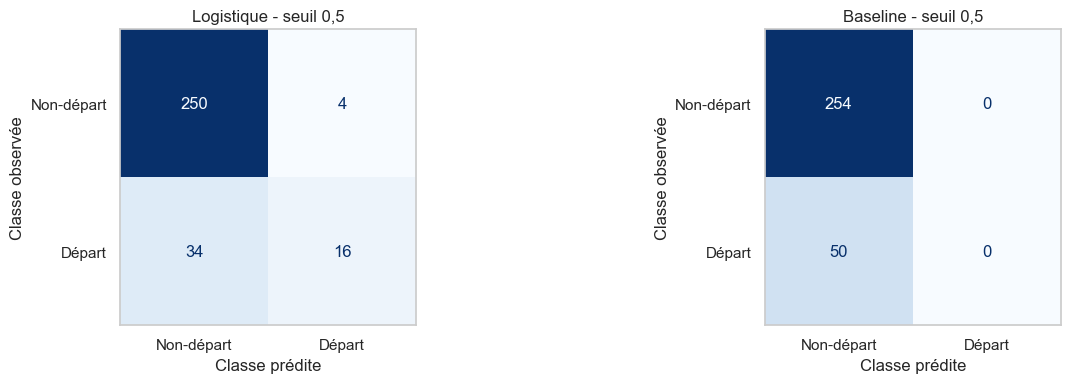

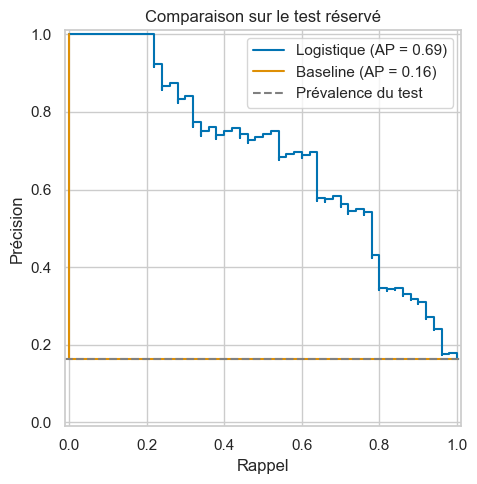

Au seuil 0,5 : 16 départs détectés sur 50 (rappel 32.0%) ; précision 80.0%.


In [6]:
test_results, predictions = evaluate_test(searches, X_test, y_test)
comparison = pd.concat([cv_results, test_results], ignore_index=True)
display(export_table(comparison, "04_comparaison_performances"))
export_table(test_results, "04_evaluation")
plot_model_comparison(y_test, predictions, prefix="04")
result = test_results.loc[test_results.modele.eq("Logistique")].iloc[0]
print(f"Au seuil 0,5 : {int(result.vrais_positifs)} départs détectés sur {int(y_test.sum())} "
      f"(rappel {result.recall:.1%}) ; précision {result.precision:.1%}.")

## 7. Lire les coefficients avec prudence
Un coefficient positif augmente le score de départ, les autres entrées étant fixées ; un négatif le réduit. Pour les quantitatives, l’unité est un écart-type d’entraînement.

Avec `drop=None`, toutes les modalités sont conservées : il n’y a pas une catégorie de référence supprimée. Un coefficient d’indicatrice isolé ne doit donc pas être présenté comme l’écart à une référence. Les coefficients sont régularisés, sensibles aux variables corrélées et ne constituent pas des tests de significativité ni des effets causaux.

In [7]:
fitted = searches["Logistique"].best_estimator_
coefficients = pd.DataFrame({"variable_transformee": fitted.named_steps["preparation"].get_feature_names_out(),
    "coefficient": fitted.named_steps["modele"].coef_[0]})
coefficients["valeur_absolue"] = coefficients.coefficient.abs()
display(export_table(coefficients.sort_values("valeur_absolue", ascending=False), "04_coefficients"))
print("Constante :", fitted.named_steps["modele"].intercept_[0])

,variable_transformee,coefficient,valeur_absolue
1,binaires__OverTime,1.207104,1.207104
47,categories_scores__JobLevel_2,-0.557512,0.557512
40,categories_scores__JobInvolvement_1,0.550643,0.550643
3,categories_scores__BusinessTravel_Travel_Frequ...,0.528904,0.528904
63,categories_scores__RelationshipSatisfaction_1,0.476366,0.476366
...,...,...,...
32,categories_scores__Education_6,-0.005845,0.005845
28,categories_scores__Education_2,-0.005548,0.005548
84,quantitatives__MonthlyRate,0.003574,0.003574
26,categories_scores__Education_0,0.002343,0.002343


Constante : -1.76298636588693


## 8. Sauvegarder le modèle et vérifier la reproductibilité
Le pipeline sauvegardé inclut son prétraitement. Les indices, plis, paramètres, versions et empreinte Excel sont enregistrés avec le préfixe 04. Les sauvegardes sont relues sur un échantillon d’entraînement, sans réévaluer le test.

In [8]:
feature_names = transformed_features(searches)
display(export_table(feature_names, "04_variables_transformees"))
metadata = save_artifacts(searches, split_rows, prefix="04")
import joblib
for name, search in searches.items():
    restored = joblib.load(MODEL_DIR / f"04_{name}.joblib")
    np.testing.assert_allclose(restored.predict_proba(X_train.iloc[:8]),
        search.best_estimator_.predict_proba(X_train.iloc[:8]))
for p, fingerprint in excel_hashes.items():
    assert sha256(p.read_bytes()).hexdigest() == fingerprint, f"Excel modifié : {p}"
print("Pipelines sauvegardés ; toutes les sources Excel sont inchangées.")

,modele,position,variable_transformee
0,Logistique,0,binaires__Gender
1,Logistique,1,binaires__OverTime
2,Logistique,2,categories_scores__BusinessTravel_Non-Travel
3,Logistique,3,categories_scores__BusinessTravel_Travel_Frequ...
4,Logistique,4,categories_scores__BusinessTravel_Travel_Rarely
...,...,...,...
88,Logistique,88,quantitatives__TrainingTimesLastYear
89,Logistique,89,quantitatives__YearsAtCompany
90,Logistique,90,quantitatives__YearsInCurrentRole
91,Logistique,91,quantitatives__YearsSinceLastPromotion


Pipelines sauvegardés ; toutes les sources Excel sont inchangées.


## Limites à retenir
Les probabilités, en particulier avec une pondération des classes, ne sont pas automatiquement bien calibrées. Un seul split et peu de départs rendent les estimations incertaines. Les anomalies conservées peuvent influencer les modèles.

La chronologie des variables est inconnue : un split correct ne suffit pas à éliminer une possible fuite temporelle. Les modèles décrivent des associations prédictives, pas les causes des départs, une discrimination ou les effets attendus d’une action RH. Aucun pays ne valide la généralisation à l’Afrique ; l’absentéisme n’est pas mesurable ici.

Le guide PDF décrit un protocole antérieur ; les anciens exports archivés ont été supprimés. Les résultats de ce parcours sont ceux des notebooks 04 et 05 actuels.